# Mandatory assignment 3

**GitHub repository:** *(https://github.com/evalyn-code/TECH2-H26-Assignment-3).*

## About the assignment

- Complete the assignment individually.
- You may use online resources, including generative AI. Include a statement
  explaining how you used AI, or state that you did not use it.

## Submission

- Submit your completed `assignment3.ipynb` on Canvas by
  **October 23, 2026, at 23:59**.

## Submission requirements

- Create a new repository from the template linked on Canvas (click **Use this
  template** > **Create a new repository**) and implement your solution in your
  GitHub repository.
- Use the TECH2 environment from the course.
- Implement your solution directly in this notebook by inserting code and text
  cells. Do not create additional notebooks or files.
- Include all requested numerical results, figures, and short written answers.
- Give each figure a title, label its axes, and include a legend where needed.
- Before you submit, make sure your GitHub repository is **publicly accessible** and include its URL at the
  top of this notebook.
- Before submission, restart the kernel and run all cells in order. Your notebook
  must run without errors and find the CSV without an absolute file path.

## Hints

- Use the material from lectures and workshops 1–3: functions, loops, NumPy,
  pandas, and Matplotlib.
- Compute group statistics using loops; there is no need to use `groupby()`
  (which we cover in lecture 4), but you can do so if you prefer.

In [237]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 


***
## Stock market participation in US households

Who participates in the stock market, and how has participation changed over time?
To answer this question, you will analyze data from the
[Survey of Consumer Finances](https://www.federalreserve.gov/econres/scfindex.htm)
(SCF), a representative survey of US households conducted every three years
from 1989 to 2022.

The file `SCF_10pct.csv` contains a 10% sample of the SCF data. The central variables of
interest for this assignment are:

1. `stocks`, which reports the value of directly held stocks (in US dollars); and
2. `equity`, which reports the value of all equity holdings (in US dollars),
   including direct stock ownership and indirect exposure through mutual funds,
   retirement accounts, and other investment vehicles.

We measure stock market participation in two ways:

- **Direct participation:** a household owns individual stocks (`stocks > 0`).
- **Overall participation:** a household holds equity directly or indirectly
  (`equity > 0`).

For each measure, the *participation rate* is the percentage of households
satisfying that condition. We therefore calculate two rates: the **direct
participation rate** and the **overall participation rate**. Direct participants
are included among overall participants, so the two rates should not be added.

## Data description

| Variable | Description |
|----------|-------------|
| `id` | Unique observation identifier |
| `year` | Survey year |
| `age` | Age of the household reference person |
| `educ` | Education level: `1`: No high school; `2`: High school; `3`: Some college; `4`: Bachelor's or higher |
| `stocks` | Value of directly held individual stocks (in US dollars) |
| `equity` | Total directly and indirectly owned stock equity (in US dollars) |

***
## Part 1 — Data preparation

1. Load `SCF_10pct.csv` into a pandas DataFrame. Print the columns contained in
   the DataFrame and their number of non-missing values.
2. Drop all observations that have missing values for any of the variables listed
   in the table above. For each variable, report how many observations you dropped
   and how many remain.
3. Keep observations with `25 <= age <= 89`, including both endpoints.
   Report how many observations you dropped and how many remain.
4. Create two 0/1 indicator columns:
   - `direct`: 1 if the household participates directly (`stocks > 0`),
     0 otherwise.
   - `overall`: 1 if the household participates directly or indirectly
     (`equity > 0`), 0 otherwise.

In [238]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 

# PART 1 - Data Preparation
# 1. Path to SCF_10pct.csv

df = pd.read_csv('SCF_10pct.csv')


In [239]:
# Print columns in DataFrame and show number of missing values
df.info(show_counts=True)

<class 'pandas.DataFrame'>
RangeIndex: 5808 entries, 0 to 5807
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   id      5808 non-null   int64  
 1   year    5808 non-null   int64  
 2   age     5808 non-null   int64  
 3   educ    5792 non-null   float64
 4   stocks  5790 non-null   float64
 5   equity  5792 non-null   float64
dtypes: float64(3), int64(3)
memory usage: 272.4 KB


In [240]:
#Part 1:2
# Drop missing values 

variables = ['id', 'year', 'age', 'educ', 'stocks', 'equity']

for var in variables:
    n_before = len(df) # number of rows before dropping
    df = df[df[var].notna()]
    n_dropped = n_before - len(df)
    print(var, 'dropped:', 'remaining:', len(df))

id dropped: remaining: 5808
year dropped: remaining: 5808
age dropped: remaining: 5808
educ dropped: remaining: 5792
stocks dropped: remaining: 5774
equity dropped: remaining: 5758


In [241]:
# Part 1:3
# Keep ages between 25 and 89 including end points
 
n_before = len(df)
df = df[(df['age'] >= 25) & (df['age'] <= 89)]
n_dropped = n_before - len(df)
print('Age filter dropped:', n_dropped, 'remaining', len(df))

Age filter dropped: 326 remaining 5432


In [242]:
# Part1:4

#Create 2 0/1 indicator columns

df['direct'] = (df['stocks'] > 0).astype(int)
df['overall'] = (df['equity'] > 0).astype(int)

In [243]:
print(df[['stocks', 'equity', 'direct', 'overall']])

        stocks     equity  direct  overall
0          0.0        0.0       0        0
1          0.0        0.0       0        0
2          0.0        0.0       0        0
4          0.0        0.0       0        0
5          0.0        0.0       0        0
...        ...        ...     ...      ...
5802       0.0        0.0       0        0
5804       0.0        0.0       0        0
5805  100000.0   100000.0       1        1
5806   40000.0  1212000.0       1        1
5807       0.0    19600.0       0        1

[5432 rows x 4 columns]


***
## Part 2 — Participation rates

You are now ready to compute the stock market participation rates for the
final sample. You will compute these in two ways: first, by writing a function
that uses a loop to compute the participation rate, and second, by using pandas's
built-in `mean()` method.

1. Write a function `participation_rate(indicator)` that takes a nonempty
   one-dimensional sequence of 0/1 values and returns the fraction of ones
   (in percent).
2. Apply your function to the final sample's `direct` and `overall`
   columns to compute the direct and overall participation rates. Report the
   results.
3. Use pandas's built-in `mean()` method to compute the direct and overall
   participation rates. Report the results.

In [244]:
# 1. Participation rate indicator using loop

def participation_rate(indicator):
   
    count = 0
    for value in indicator:
        count = count + value
    rate = count / len(indicator) * 100

    return rate






In [245]:
# 2. Compute direct and overall participation rates
direct_rate = participation_rate(df['direct'])
print(round(direct_rate, 2))

overall_rate = participation_rate(df['overall'])
print(round(overall_rate, 2))


16.96
49.41


In [246]:
# 3. Compute mean of direct and overall rates using Pandas

direct_rate_mean = df['direct'].mean() * 100
print(round(direct_rate_mean, 2), '%')

overall_rate_mean = df['overall'].mean() * 100
print(round(overall_rate_mean, 2), '%')



16.96 %
49.41 %


***
## Part 3 — Participation by education

1. Loop over education categories 1–4. For each category, calculate the direct
   participation rate and the overall participation rate (in percent).
2. Display the results, rounding rates to one decimal place.
3. Create a figure with two subplots, one for each rate, containing bar charts
   of participation rates across education categories.
4. In two or three sentences, describe the education pattern.

In [247]:
def participation_rate(indicator):
    """
    Return the percentage of ones in a sequence of 0/1 values
    """
    total = 0
    for value in indicator:
        total = total + value
    rate = total / len(indicator) * 100
    return rate

In [248]:
# 1 and 2 Loop over education categories 1 - 4

educ_levels = range(1, 5)
direct_by_educ = []
overall_by_educ = []

for educ in educ_levels:
    df_educ = df[df['educ'] == educ]

    direct_rate = participation_rate(df_educ['direct'])
    overall_rate = participation_rate(df_educ['overall'])

# Store them

    direct_by_educ.append(direct_rate)
    overall_by_educ.append(overall_rate)

    print(f'Education level {educ}')
    print(f'  Households:   {len(df_educ)}')
    print(f'  Direct  (%):  {direct_rate:.1f}')
    print(f'  Overall (%):  {overall_rate:.1f}')

Education level 1
  Households:   765
  Direct  (%):  4.4
  Overall (%):  17.3
Education level 2
  Households:   1589
  Direct  (%):  11.4
  Overall (%):  39.9
Education level 3
  Households:   1368
  Direct  (%):  13.5
  Overall (%):  48.3
Education level 4
  Households:   1710
  Direct  (%):  30.5
  Overall (%):  73.5


In [249]:
# 1 and 2. Trying a different code

for educ_level in range(1, 5):
    df_educ = df[df['educ'] == educ_level]

    direct_rate = participation_rate(df_educ['direct'])
    overall_rate = participation_rate(df_educ['overall'])

    print('Education level:', educ_level), '%'
    print('Direct:', round(direct_rate, 1), '%')
    print('Overall:', round(overall_rate, 1), '%')

    print()

Education level: 1
Direct: 4.4 %
Overall: 17.3 %

Education level: 2
Direct: 11.4 %
Overall: 39.9 %

Education level: 3
Direct: 13.5 %
Overall: 48.3 %

Education level: 4
Direct: 30.5 %
Overall: 73.5 %



In [250]:
# 2 Compute education results table
import pandas as pd

educ_names = ['No High schl', 'H schl', 'Some college', 'Bachelor']

results_educ = pd.DataFrame({
    'Education': educ_names,
    'Direct (&)': direct_by_educ,
    'Overall (&)': overall_by_educ,
})

results_educ

,Education,Direct (&),Overall (&)
0,No High schl,4.444444,17.254902
1,H schl,11.390812,39.899308
2,Some college,13.523392,48.318713
3,Bachelor,30.467836,73.508772


In [251]:
# 2b Round off results table to one decimal place
results_educ.round(1)

,Education,Direct (&),Overall (&)
0,No High schl,4.4,17.3
1,H schl,11.4,39.9
2,Some college,13.5,48.3
3,Bachelor,30.5,73.5


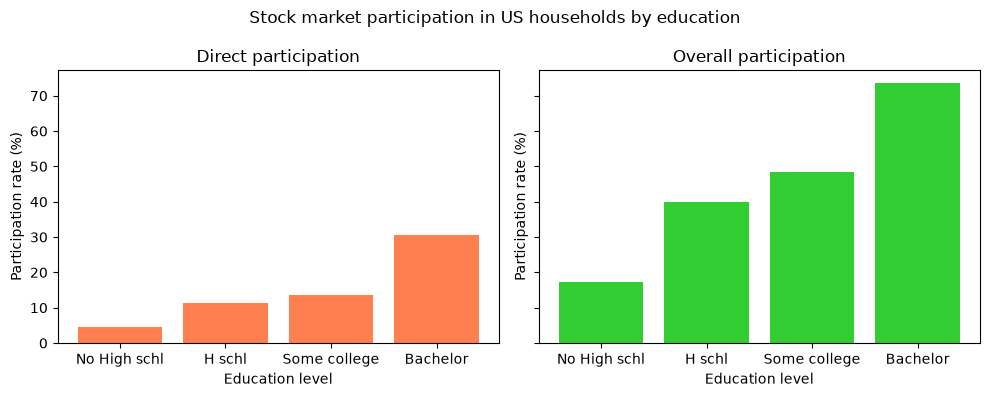

In [252]:
#  Bar charts of participation rates across education categories

import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(10,4), sharey=True)

# Direct Participation

axes[0].bar(educ_names, direct_by_educ, color='coral')
axes[0].set_title('Direct participation')
axes[0].set_xlabel('Education level')
axes[0].set_ylabel('Participation rate (%)')

axes[1].bar(educ_names, overall_by_educ, color='limegreen')
axes[1].set_title('Overall participation')
axes[1].set_xlabel('Education level')
axes[1].set_ylabel('Participation rate (%)')

fig.suptitle('Stock market participation in US households by education')
fig.tight_layout()

In [253]:
# 4
# Both rates rise steadily with education. At every education level, overall participation is far above direct participation.

***
## Part 4 — Participation over time

1. Loop over years. For each year, compute the direct participation rate and the
   overall participation rate.
2. Create a line plot showing both participation rates over time in a single figure.
3. Report the changes from 1989 to 2022 in the direct and overall participation
   rates, both in percentage points.
4. Describe the main time patterns in two or three sentences.

In [254]:
# 1a. Direct and overall participation rates for each year

years = range(1989, 2023, 3)
print(list(years))

[1989, 1992, 1995, 1998, 2001, 2004, 2007, 2010, 2013, 2016, 2019, 2022]


In [255]:
#1b
direct_by_year = []
overall_by_year = []

for year in years:
    df_year = df[df['year'] == year]

    direct_rate = participation_rate(df_year['direct'])
    overall_rate = participation_rate(df_year['overall'])

    direct_by_year.append(direct_rate)
    overall_by_year.append(overall_rate)

print(f'{year}: direct {direct_rate:.1f} %, overall {overall_rate:.1f} %')

2022: direct 19.2 %, overall 54.3 %


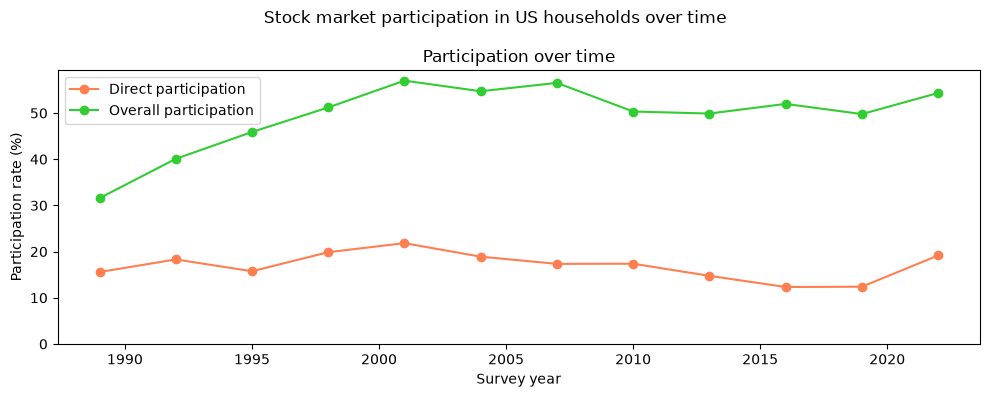

In [256]:
#2

fig, axes = plt.subplots(figsize=(10, 4))

# Direct participation
axes.plot(years, direct_by_year, color='coral', marker='o', label='Direct participation')

# Overall participation
axes.plot(years, overall_by_year, color='limegreen', marker='o', label='Overall participation')

axes.set_title('Participation over time')
axes.set_xlabel('Survey year')
axes.set_ylabel('Participation rate (%)')
axes.set_ylim(bottom=0)
axes.legend()

fig.suptitle('Stock market participation in US households over time')
fig.tight_layout()



In [257]:
# 3 Changes from 1989 to 2022 in percentage points


direct_1989 = direct_by_year[0]
direct_2022 = direct_by_year[-1]
direct_change = direct_2022 - direct_1989

overall_1989 = overall_by_year[0]
overall_2022 = overall_by_year[-1]
overall_change = overall_2022 - overall_1989

print(f'Direct:  {direct_1989:.1f} % in 1989, {direct_2022:.1f} % in 2022')
print(f'Overall: {overall_1989:.1f} % in 1989, {overall_2022:.1f} % in 2022')


Direct:  15.6 % in 1989, 19.2 % in 2022
Overall: 31.6 % in 1989, 54.3 % in 2022


Both direct and overall stock market participation has been increasing from 1989 to 2001, reaching their highest levels around 2001. 
After 2001, overall participation remained relatively high but fluctuated, while direct participation generally declined until 2017–2019 before rising again in 2022. 
Overall participation was consistently higher than direct participation throughout the period.

***
## AI-use statement

Students must describe their own use of AI here, or state that they did not use it.

I used Claude as a tutor in the assignment. It explained concepts step by step so that I could understand better before applying them in the assignment, giving me the chance to learn. Whenever I got stuck or got errors, I used it to help me identify them, eg: spelling mistakes or misplaced code, then I'd correct them and only sought its assistance after really trying. I ran all the code myself and saw the results making sense.